## Experiment 6 - Time Series Analysis of Website Traffic

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
# Load dataset
data = pd.read_csv('../data/website_traffic.csv', parse_dates=['Date'], index_col='Date')

In [3]:
# Handle missing values by interpolation
data = data.interpolate()

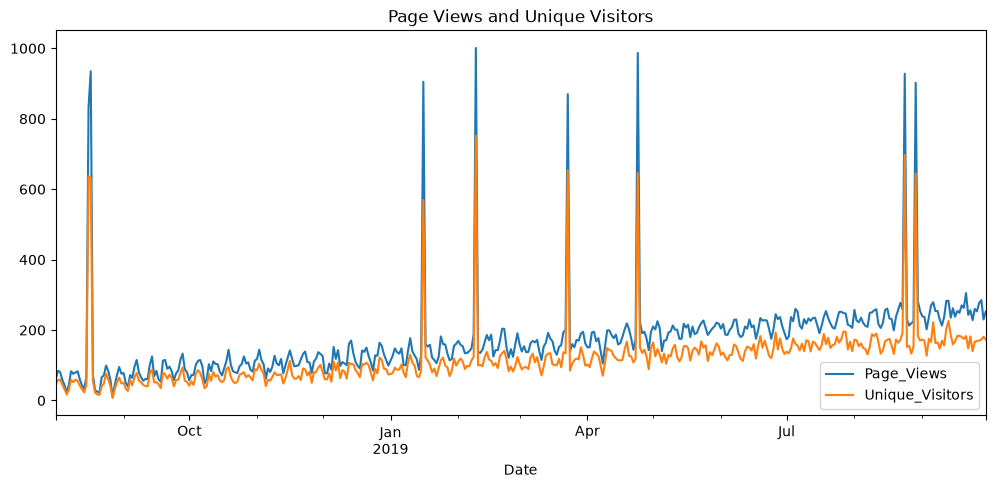

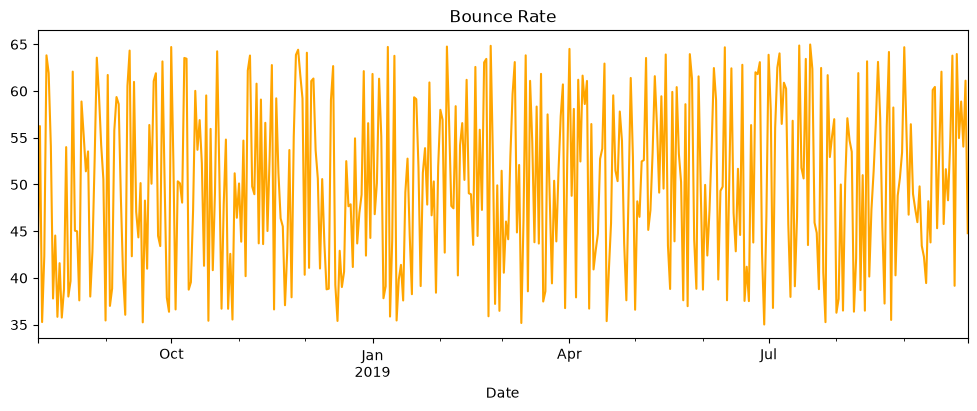

In [4]:
# Plot the time series data
data[['Page_Views', 'Unique_Visitors']].plot(figsize=(12, 5))
plt.title('Page Views and Unique Visitors')
plt.show()
data['Bounce_Rate'].plot(figsize=(12, 4), color='orange')
plt.title('Bounce Rate')
plt.show()

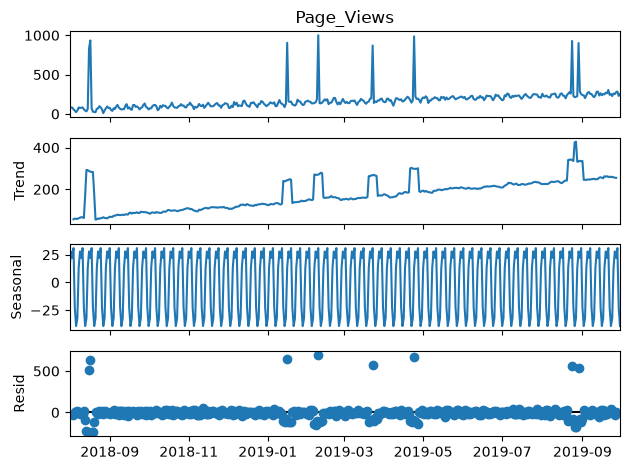

In [5]:
# Time Series Decomposition
decomposition = seasonal_decompose(data['Page_Views'], model='additive')
decomposition.plot()
plt.show()

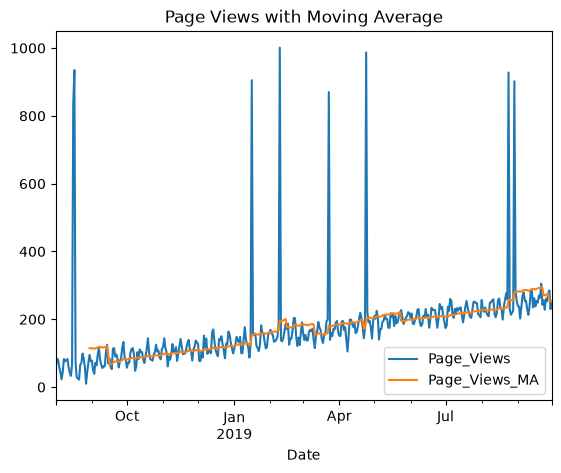

In [6]:
# Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

Anomalies detected:
             Page_Views  Page_Views_Z
Date                                
2018-08-16       833.0      5.458491
2018-08-17       935.0      6.301658
2019-01-16       905.0      6.053668
2019-02-09      1001.0      6.847236
2019-03-23       870.0      5.764346
2019-04-24       987.0      6.731508
2019-08-24       928.0      6.243793
2019-08-29       902.0      6.028869


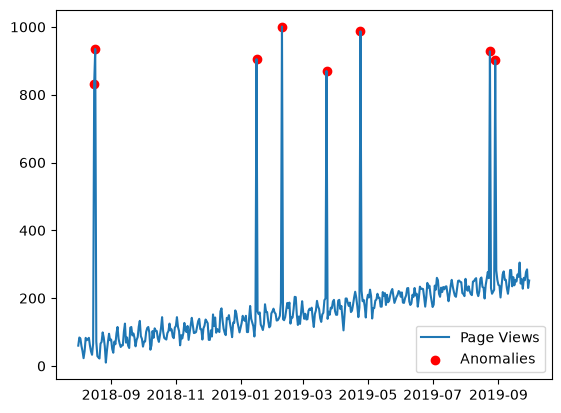

In [7]:
# Anomaly Detection
data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]
print("Anomalies detected:\n", anomalies[['Page_Views', 'Page_Views_Z']])
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()